In [9]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

In [7]:
df=pd.read_csv("/Users/amankumar/Desktop/ML_LEARNING/Dataset/used_car_resale_ridge_lasso.csv")
df

,Car_Age_Years,Km_Driven,Engine_CC,Max_Power_BHP,Mileage_Kmpl,Owner_Count,Seats,Fuel_Type,Transmission,Seller_Type,Resale_Price_INR
0,1,32411,1000,35.0,25.3,1,5,Diesel,Automatic,Individual,1367653
1,12,155794,1500,120.5,14.7,1,7,Diesel,Manual,Dealer,1295648
2,10,91135,1000,77.4,21.7,3,6,Petrol,Manual,Individual,465096
3,7,92127,2000,103.3,17.3,1,5,Petrol,Automatic,Individual,1707259
4,6,77935,2000,110.8,17.4,1,5,Petrol,Automatic,Individual,1680825
...,...,...,...,...,...,...,...,...,...,...,...
3995,5,30444,2000,135.8,19.3,1,5,Petrol,Manual,Individual,2167849
3996,0,66689,1800,112.0,22.0,3,5,Diesel,Manual,Dealer,2300495
3997,13,97604,800,75.0,25.6,1,5,Diesel,Manual,Dealer,901899
3998,11,137242,2500,153.7,12.2,2,4,Diesel,Manual,Individual,1784195


In [10]:
df.shape

(4000, 11)

In [11]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 11 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Car_Age_Years     4000 non-null   int64  
 1   Km_Driven         4000 non-null   int64  
 2   Engine_CC         4000 non-null   int64  
 3   Max_Power_BHP     3920 non-null   float64
 4   Mileage_Kmpl      3900 non-null   float64
 5   Owner_Count       4000 non-null   int64  
 6   Seats             4000 non-null   int64  
 7   Fuel_Type         3940 non-null   str    
 8   Transmission      4000 non-null   str    
 9   Seller_Type       4000 non-null   str    
 10  Resale_Price_INR  4000 non-null   int64  
dtypes: float64(2), int64(6), str(3)
memory usage: 426.1 KB


In [12]:
df.isnull().sum()

Car_Age_Years         0
Km_Driven             0
Engine_CC             0
Max_Power_BHP        80
Mileage_Kmpl        100
Owner_Count           0
Seats                 0
Fuel_Type            60
Transmission          0
Seller_Type           0
Resale_Price_INR      0
dtype: int64

In [13]:
df.columns

Index(['Car_Age_Years', 'Km_Driven', 'Engine_CC', 'Max_Power_BHP',
       'Mileage_Kmpl', 'Owner_Count', 'Seats', 'Fuel_Type', 'Transmission',
       'Seller_Type', 'Resale_Price_INR'],
      dtype='str')

In [18]:
df.duplicated().sum()

np.int64(0)

In [16]:
df["Fuel_Type"].value_counts()

Fuel_Type
Petrol      1848
Diesel      1454
CNG          469
Electric     169
Name: count, dtype: int64

In [14]:
df.describe()

,Car_Age_Years,Km_Driven,Engine_CC,Max_Power_BHP,Mileage_Kmpl,Owner_Count,Seats,Resale_Price_INR
count,4000.000000,4000.000000,4000.000000,3920.000000,3900.000000,4000.000000,4000.000000,4.000000e+03
mean,7.508000,102950.340750,1495.625000,97.053316,19.971795,1.416250,5.485000,1.365752e+06
std,4.607412,40062.780861,465.416494,31.005987,3.188293,0.695059,0.979548,5.893417e+05
min,0.000000,3000.000000,800.000000,35.000000,8.500000,1.000000,4.000000,7.000000e+04
25%,3.000000,73147.000000,1200.000000,74.075000,17.800000,1.000000,5.000000,9.407168e+05
50%,7.000000,102073.500000,1500.000000,95.600000,20.100000,1.000000,5.000000,1.347992e+06
75%,12.000000,132412.000000,1800.000000,118.300000,22.200000,2.000000,6.000000,1.778831e+06
max,15.000000,214418.000000,2500.000000,207.000000,29.700000,4.000000,8.000000,3.324832e+06


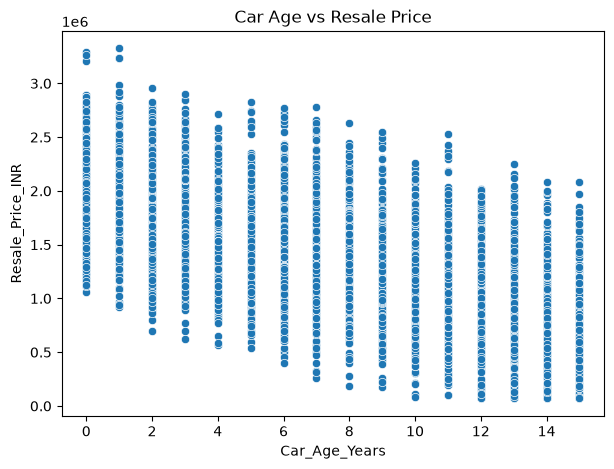

In [19]:
plt.figure(figsize=(7,5))

sns.scatterplot(
    data=df,
    x="Car_Age_Years",
    y="Resale_Price_INR"
)

plt.title("Car Age vs Resale Price")
plt.show()

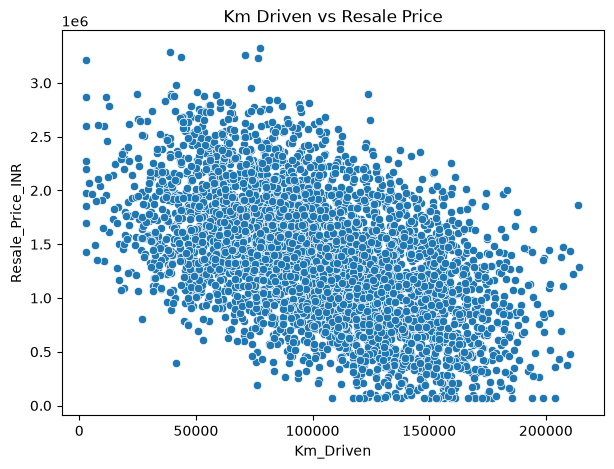

In [20]:
plt.figure(figsize=(7,5))

sns.scatterplot(
    data=df,
    x="Km_Driven",
    y="Resale_Price_INR"
)

plt.title("Km Driven vs Resale Price")
plt.show()

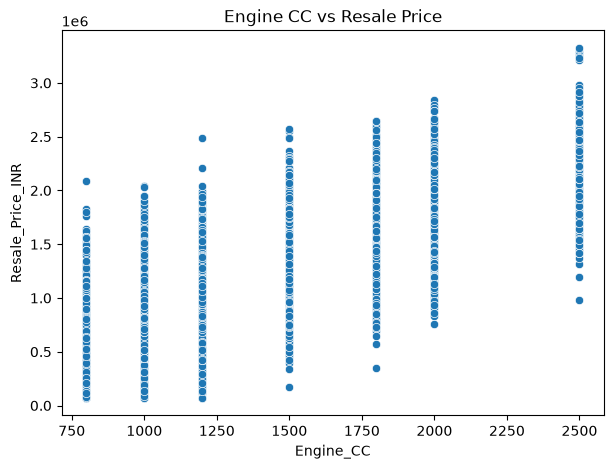

In [21]:
plt.figure(figsize=(7,5))

sns.scatterplot(
    data=df,
    x="Engine_CC",
    y="Resale_Price_INR"
)

plt.title("Engine CC vs Resale Price")
plt.show()

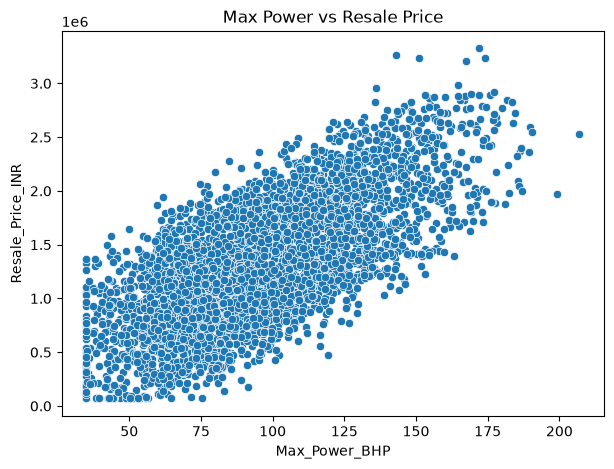

In [22]:
plt.figure(figsize=(7,5))

sns.scatterplot(
    data=df,
    x="Max_Power_BHP",
    y="Resale_Price_INR"
)

plt.title("Max Power vs Resale Price")
plt.show()

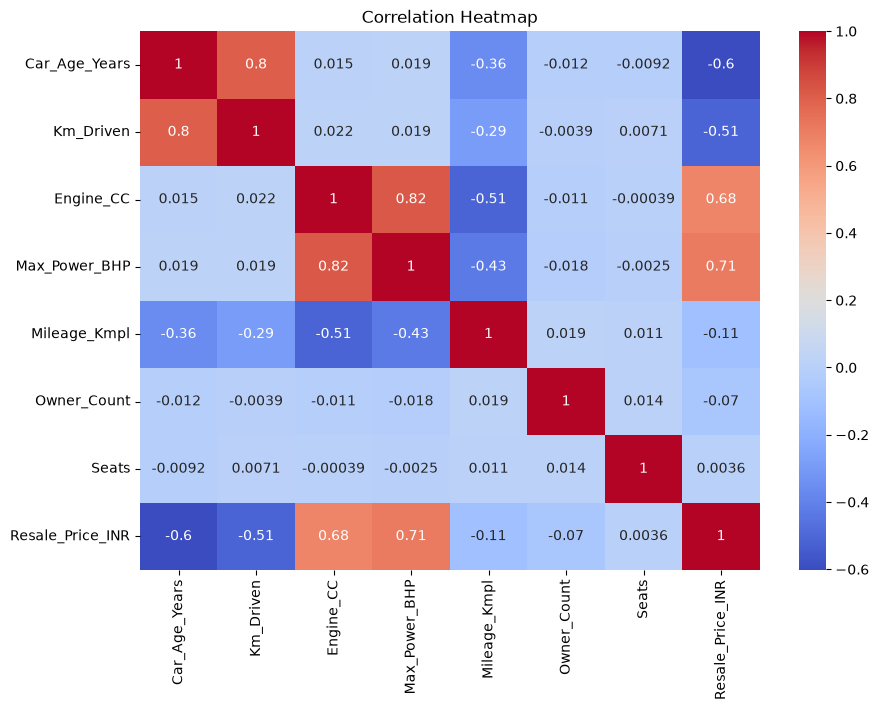

In [23]:
corr = df.select_dtypes(include=np.number).corr()

plt.figure(figsize=(10,7))

sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm"
)

plt.title("Correlation Heatmap")
plt.show()

In [24]:
corr["Resale_Price_INR"].sort_values(ascending=False)

Resale_Price_INR    1.000000
Max_Power_BHP       0.705874
Engine_CC           0.678470
Seats               0.003638
Owner_Count        -0.070073
Mileage_Kmpl       -0.111222
Km_Driven          -0.511752
Car_Age_Years      -0.602643
Name: Resale_Price_INR, dtype: float64

In [25]:
X = df.drop("Resale_Price_INR", axis=1)
y = df["Resale_Price_INR"]

In [26]:
X.head()

,Car_Age_Years,Km_Driven,Engine_CC,Max_Power_BHP,Mileage_Kmpl,Owner_Count,Seats,Fuel_Type,Transmission,Seller_Type
0,1,32411,1000,35.0,25.3,1,5,Diesel,Automatic,Individual
1,12,155794,1500,120.5,14.7,1,7,Diesel,Manual,Dealer
2,10,91135,1000,77.4,21.7,3,6,Petrol,Manual,Individual
3,7,92127,2000,103.3,17.3,1,5,Petrol,Automatic,Individual
4,6,77935,2000,110.8,17.4,1,5,Petrol,Automatic,Individual


In [27]:
y.head()

0    1367653
1    1295648
2     465096
3    1707259
4    1680825
Name: Resale_Price_INR, dtype: int64

In [29]:
from sklearn.model_selection import train_test_split
X_train , X_test , y_train , y_test = train_test_split(
    X,y, test_size=0.2,random_state=42
)

In [30]:
X_train.shape, X_test.shape

((3200, 10), (800, 10))

In [31]:
num_cols = X.select_dtypes(include=np.number).columns
cat_cols = X.select_dtypes(include="object").columns

print("Numerical:", list(num_cols))
print("Categorical:", list(cat_cols))

Numerical: ['Car_Age_Years', 'Km_Driven', 'Engine_CC', 'Max_Power_BHP', 'Mileage_Kmpl', 'Owner_Count', 'Seats']
Categorical: ['Fuel_Type', 'Transmission', 'Seller_Type']


/var/folders/dq/q7st889528v76ffzrt2fk2_m0000gn/T/ipykernel_43486/2674081514.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X.select_dtypes(include="object").columns


In [32]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

# Numerical pipeline
num_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical pipeline
cat_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both
preprocessor = ColumnTransformer([
    ("num", num_pipeline, num_cols),
    ("cat", cat_pipeline, cat_cols)
])

In [33]:
from sklearn.linear_model import LinearRegression

linear_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LinearRegression())
])

In [34]:
linear_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](10,)","['Car_Age_Years','Km_Driven','Engine_CC',...,'Fuel_Type','Transmission', 'Seller_Type']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,10
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This s

In [35]:
y_pred_linear = linear_model.predict(X_test)

In [36]:
y_pred_linear[:5]

array([1239620.78771306, 1225035.97357204, 1880654.80588955,
        892832.94276122, 1619699.26985971])

In [37]:
y_test.head().values

array([1281594, 1035134, 1804437,  981160, 1760005])

In [38]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

mae_linear = mean_absolute_error(y_test, y_pred_linear)

mse_linear = mean_squared_error(y_test, y_pred_linear)

rmse_linear = np.sqrt(mse_linear)

r2_linear = r2_score(y_test, y_pred_linear)

print("Linear Regression")
print("MAE :", mae_linear)
print("RMSE:", rmse_linear)
print("R²  :", r2_linear)

Linear Regression
MAE : 112378.67833017593
RMSE: 145013.04118742445
R²  : 0.9418187601283028


In [39]:
from sklearn.linear_model import Ridge

In [40]:
ridge_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", Ridge(alpha=1.0))
])

In [41]:
ridge_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](10,)","['Car_Age_Years','Km_Driven','Engine_CC',...,'Fuel_Type','Transmission', 'Seller_Type']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,10
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This s

In [42]:
y_pred_ridge = ridge_model.predict(X_test)

In [43]:
y_pred_ridge[:5]

array([1239812.39284714, 1225419.46185478, 1880448.82007761,
        892793.73868284, 1619703.7255356 ])

In [44]:
mae_ridge = mean_absolute_error(y_test, y_pred_ridge)

mse_ridge = mean_squared_error(y_test, y_pred_ridge)

rmse_ridge = np.sqrt(mse_ridge)

r2_ridge = r2_score(y_test, y_pred_ridge)

print("Ridge Regression")
print("MAE :", mae_ridge)
print("RMSE:", rmse_ridge)
print("R²  :", r2_ridge)

Ridge Regression
MAE : 112369.68582092221
RMSE: 145008.7039345198
R²  : 0.9418222404080873


In [45]:
alphas = [0.01, 0.1, 1, 10, 100]

In [46]:
ridge_results = []

for alpha in alphas:

    ridge_model = Pipeline([
        ("preprocessor", preprocessor),
        ("model", Ridge(alpha=alpha))
    ])

    ridge_model.fit(X_train, y_train)

    y_pred = ridge_model.predict(X_test)

    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2 = r2_score(y_test, y_pred)

    ridge_results.append([alpha, mae, rmse, r2])

In [47]:
ridge_results_df = pd.DataFrame(
    ridge_results,
    columns=["Alpha", "MAE", "RMSE", "R2"]
)

ridge_results_df

,Alpha,MAE,RMSE,R2
0,0.01,112378.583079,145012.990144,0.941819
1,0.10,112377.726291,145012.537794,0.941819
2,1.00,112369.685821,145008.703935,0.941822
3,10.00,112342.563549,145032.688716,0.941803
4,100.00,114564.029738,148076.863332,0.939334


In [48]:
from sklearn.linear_model import Lasso

In [49]:
lasso_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", Lasso(alpha=1.0))
])

In [50]:
lasso_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](10,)","['Car_Age_Years','Km_Driven','Engine_CC',...,'Fuel_Type','Transmission', 'Seller_Type']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,10
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This s

In [51]:
y_pred_lasso = lasso_model.predict(X_test)

In [52]:
mae_lasso = mean_absolute_error(y_test, y_pred_lasso)

rmse_lasso = np.sqrt(
    mean_squared_error(y_test, y_pred_lasso)
)

r2_lasso = r2_score(y_test, y_pred_lasso)

print("Lasso Regression")
print("MAE :", mae_lasso)
print("RMSE:", rmse_lasso)
print("R²  :", r2_lasso)

Lasso Regression
MAE : 112378.36003289523
RMSE: 145012.88468931342
R²  : 0.9418188857066528


In [53]:
alphas = [0.001, 0.01, 0.1, 1, 10, 100]

In [54]:
lasso_results = []

for alpha in alphas:

    lasso_model = Pipeline([
        ("preprocessor", preprocessor),
        ("model", Lasso(alpha=alpha, max_iter=10000))
    ])

    lasso_model.fit(X_train, y_train)

    y_pred = lasso_model.predict(X_test)

    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2 = r2_score(y_test, y_pred)

    lasso_results.append([alpha, mae, rmse, r2])

In [55]:
lasso_results_df = pd.DataFrame(
    lasso_results,
    columns=["Alpha", "MAE", "RMSE", "R2"]
)

lasso_results_df

,Alpha,MAE,RMSE,R2
0,0.001,112378.678011,145013.041032,0.941819
1,0.010,112378.675133,145013.039643,0.941819
2,0.100,112378.646425,145013.025646,0.941819
3,1.000,112378.360033,145012.884689,0.941819
4,10.000,112375.504336,145011.478750,0.941820
5,100.000,112349.794844,144999.447317,0.941830


In [56]:
comparison = pd.DataFrame({
    "Model": ["Linear Regression", "Ridge", "Lasso"],
    "MAE": [mae_linear, mae_ridge, mae_lasso],
    "RMSE": [rmse_linear, rmse_ridge, rmse_lasso],
    "R2": [r2_linear, r2_ridge, r2_lasso]
})

comparison

,Model,MAE,RMSE,R2
0,Linear Regression,112378.678330,145013.041187,0.941819
1,Ridge,112369.685821,145008.703935,0.941822
2,Lasso,112378.360033,145012.884689,0.941819


In [57]:
best_lasso = Pipeline([
    ("preprocessor", preprocessor),
    ("model", Lasso(alpha=0.1, max_iter=10000))
])

best_lasso.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](10,)","['Car_Age_Years','Km_Driven','Engine_CC',...,'Fuel_Type','Transmission', 'Seller_Type']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,10
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This s

In [58]:
feature_names = best_lasso.named_steps["preprocessor"].get_feature_names_out()

len(feature_names)

15

In [59]:
lasso_coefficients = best_lasso.named_steps["model"].coef_

coef_df = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": lasso_coefficients
})

coef_df

,Feature,Coefficient
0,num__Car_Age_Years,-3.111734e+05
1,num__Km_Driven,-5.681181e+04
2,num__Engine_CC,2.054672e+05
3,num__Max_Power_BHP,2.606979e+05
4,num__Mileage_Kmpl,2.047866e+04
5,num__Owner_Count,-4.158122e+04
6,num__Seats,-3.320616e+02
7,cat__Fuel_Type_CNG,-6.663239e+04
8,cat__Fuel_Type_Diesel,8.026218e+04
9,cat__Fuel_Type_Electric,3.095793e+05


In [60]:
coef_df[coef_df["Coefficient"] == 0]

,Feature,Coefficient


In [61]:
from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import Ridge

ridge_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", Ridge())
])

param_grid = {
    "model__alpha": [0.001, 0.01, 0.1, 1, 10, 100]
}

ridge_grid = GridSearchCV(
    ridge_pipeline,
    param_grid,
    cv=5,
    scoring="neg_root_mean_squared_error"
)

ridge_grid.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","Pipeline(step...l', Ridge())])"
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'model__alpha': [0.001, 0.01, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'neg_root_mean_squared_error'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Controls the verbosity of informa

In [62]:
print("Best Alpha:", ridge_grid.best_params_)
print("Best CV RMSE:", -ridge_grid.best_score_)

Best Alpha: {'model__alpha': 1}
Best CV RMSE: 148722.45231143007


In [63]:
best_ridge = ridge_grid.best_estimator_

y_pred_ridge_best = best_ridge.predict(X_test)

print("Ridge Test MAE :", mean_absolute_error(y_test, y_pred_ridge_best))
print("Ridge Test RMSE:", np.sqrt(mean_squared_error(y_test, y_pred_ridge_best)))
print("Ridge Test R²  :", r2_score(y_test, y_pred_ridge_best))

Ridge Test MAE : 112369.68582092221
Ridge Test RMSE: 145008.7039345198
Ridge Test R²  : 0.9418222404080873


In [64]:
from sklearn.linear_model import Lasso

lasso_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", Lasso(max_iter=10000))
])

param_grid = {
    "model__alpha": [0.001, 0.01, 0.1, 1, 10, 100]
}

lasso_grid = GridSearchCV(
    lasso_pipeline,
    param_grid,
    cv=5,
    scoring="neg_root_mean_squared_error"
)

lasso_grid.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...iter=10000))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'model__alpha': [0.001, 0.01, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'neg_root_mean_squared_error'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Controls the verbosity of informati

In [65]:
print("Best Alpha:", lasso_grid.best_params_)
print("Best CV RMSE:", -lasso_grid.best_score_)

Best Alpha: {'model__alpha': 100}
Best CV RMSE: 148722.87275264648


In [66]:
best_lasso = lasso_grid.best_estimator_

y_pred_lasso_best = best_lasso.predict(X_test)

print("Lasso Test MAE :", mean_absolute_error(y_test, y_pred_lasso_best))
print("Lasso Test RMSE:", np.sqrt(mean_squared_error(y_test, y_pred_lasso_best)))
print("Lasso Test R²  :", r2_score(y_test, y_pred_lasso_best))

Lasso Test MAE : 112349.79484402055
Lasso Test RMSE: 144999.44731739885
Lasso Test R²  : 0.9418296677147578


In [67]:
comparison = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Ridge",
        "Lasso"
    ],
    "MAE": [
        mae_linear,
        mean_absolute_error(y_test, y_pred_ridge_best),
        mean_absolute_error(y_test, y_pred_lasso_best)
    ],
    "RMSE": [
        rmse_linear,
        np.sqrt(mean_squared_error(y_test, y_pred_ridge_best)),
        np.sqrt(mean_squared_error(y_test, y_pred_lasso_best))
    ],
    "R2": [
        r2_linear,
        r2_score(y_test, y_pred_ridge_best),
        r2_score(y_test, y_pred_lasso_best)
    ]
})

comparison

,Model,MAE,RMSE,R2
0,Linear Regression,112378.678330,145013.041187,0.941819
1,Ridge,112369.685821,145008.703935,0.941822
2,Lasso,112349.794844,144999.447317,0.941830


In [68]:
best_model = comparison.loc[comparison["RMSE"].idxmin()]

print("Best Model:", best_model["Model"])
print("RMSE:", best_model["RMSE"])
print("MAE:", best_model["MAE"])
print("R²:", best_model["R2"])

Best Model: Lasso
RMSE: 144999.44731739885
MAE: 112349.79484402055
R²: 0.9418296677147578


In [69]:
best_model_name = comparison.loc[
    comparison["RMSE"].idxmin(), "Model"
]

print("Final Best Model:", best_model_name)

Final Best Model: Lasso


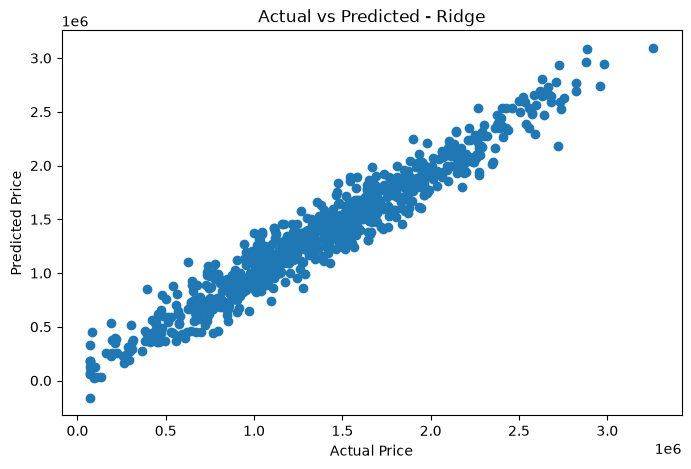

In [70]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred_ridge_best)

plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Actual vs Predicted - Ridge")

plt.show()

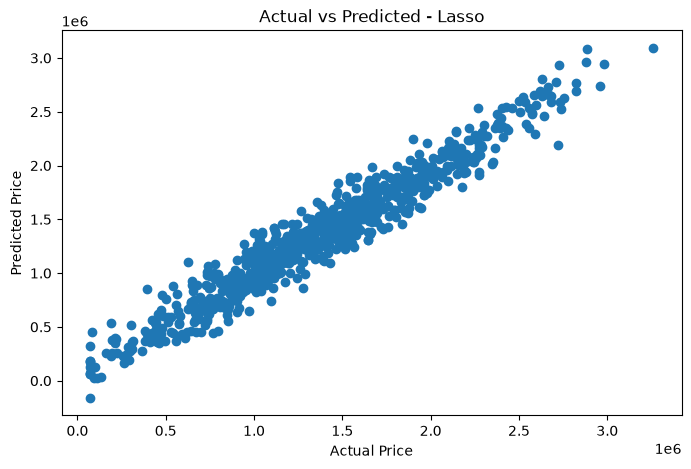

In [71]:
plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred_lasso_best)

plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Actual vs Predicted - Lasso")

plt.show()

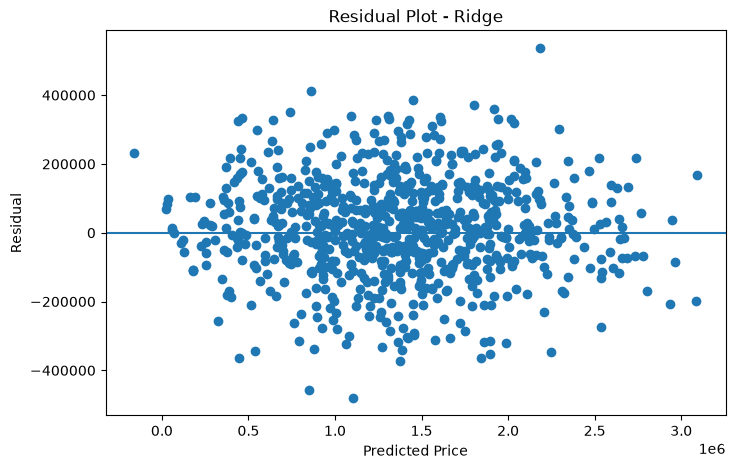

In [72]:
residuals = y_test - y_pred_ridge_best

plt.figure(figsize=(8, 5))

plt.scatter(y_pred_ridge_best, residuals)

plt.axhline(y=0)

plt.xlabel("Predicted Price")
plt.ylabel("Residual")
plt.title("Residual Plot - Ridge")

plt.show()

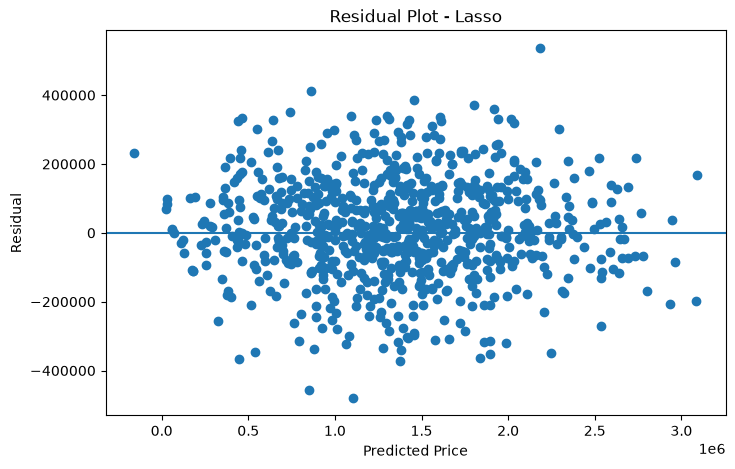

In [73]:
residuals = y_test - y_pred_lasso_best

plt.figure(figsize=(8, 5))

plt.scatter(y_pred_lasso_best, residuals)

plt.axhline(y=0)

plt.xlabel("Predicted Price")
plt.ylabel("Residual")
plt.title("Residual Plot - Lasso")

plt.show()